# Phase 3: playing with RL on the toy Sudoku dLLM

This notebook walks through phase 3 step by step.

- Every cell loads committed results from `results/phase3/`. One small live demo runs on CPU if the local checkpoint exists.
- Every number traces back to a command in `experiments/3.x/README.md`. Each of those READMEs has a prediction that was committed before the runs, and a check of that prediction afterwards.
- The summary with limitations is `results/phase3/SUMMARY.md`.

Everything here is a toy: a 0.8M-parameter masked diffusion model on 4×4 Sudoku. Nothing is a new method.

In [1]:
import json, os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, torch
from IPython.display import Image, display
from phase2.utils import CACHE, load_cfg
R = Path("results/phase3")
HAVE_CKPT = (CACHE / "sft" / "sft_weak.pt").exists()
pd.set_option("display.precision", 3)

def show(exp, table, image=None, cols=None):
    df = pd.read_csv(R / exp / table)
    display(df[cols] if cols else df)
    if image:
        display(Image(R / exp / image))

print("torch", torch.__version__, "| local checkpoints present:", HAVE_CKPT)

torch 2.15.0 | local checkpoints present: True


## 3.0 A generic trainer that reproduces phase 2

The phase 3 trainer has a pluggable objective and reward and logs extra diagnostics. Before using it, the phase 2 wd1 and positive-only runs were repeated with it.

**Shows:** same solve rates as phase 2 for every seed, so later differences come from the objective or the reward.
**Does not show:** anything new about wd1.

,variant,source,n,final_val_mean,final_val_std,final_test_mean,final_test_std,min_val_mean,min_val_step_median
0,positive-only (w⁻=0),phase2,3,0.944,0.017,0.932,0.016,0.108,100.0
1,positive-only (w⁻=0),phase3,3,0.944,0.017,0.932,0.016,0.108,100.0
2,wd1 (τ=1),phase2,3,0.731,0.015,0.738,0.005,0.420,0.0
3,wd1 (τ=1),phase3,3,0.731,0.015,0.738,0.005,0.420,0.0


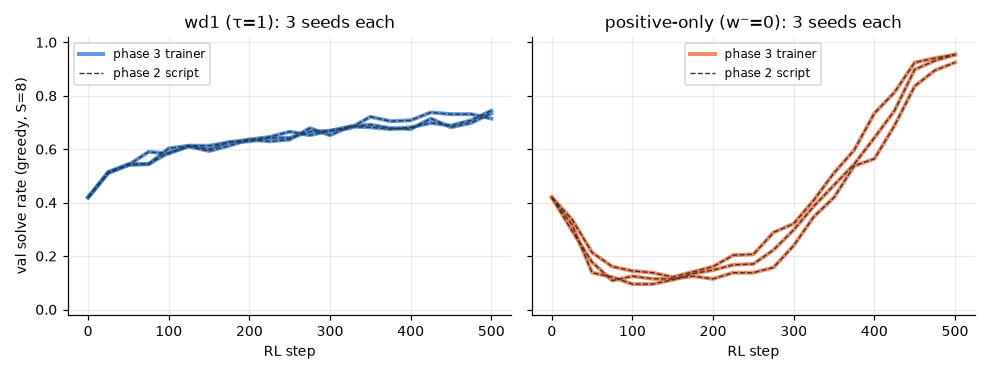

In [2]:
display(pd.read_csv(R / "repro_3.0_summary.csv"))
display(Image(R / "repro_3.0.png"))

## 3.1a Was step 500 too early?

Phase 2 stopped at 500 RL steps with wd1 still improving. Here both variants run for 2000 steps with 5 seeds.

**Shows:** the ranking holds. wd1 narrows the gap from 20 points to 9 but stays behind in every seed. By the end more than 90% of the groups have equal rewards and give no gradient.
**Does not show:** why. The standard horizon for the rest of the phase was fixed at 1500 steps by a rule written before the runs.

,variant,val_solve@500_mean,val_solve@500_std,val_solve@1000_mean,val_solve@1000_std,val_solve@1500_mean,val_solve@1500_std,val_solve@2000_mean,val_solve@2000_std
0,positive-only (w⁻=0),0.951,0.015,0.992,0.005,0.994,0.005,0.997,0.003
1,wd1 (τ=1),0.733,0.012,0.843,0.017,0.895,0.009,0.909,0.021


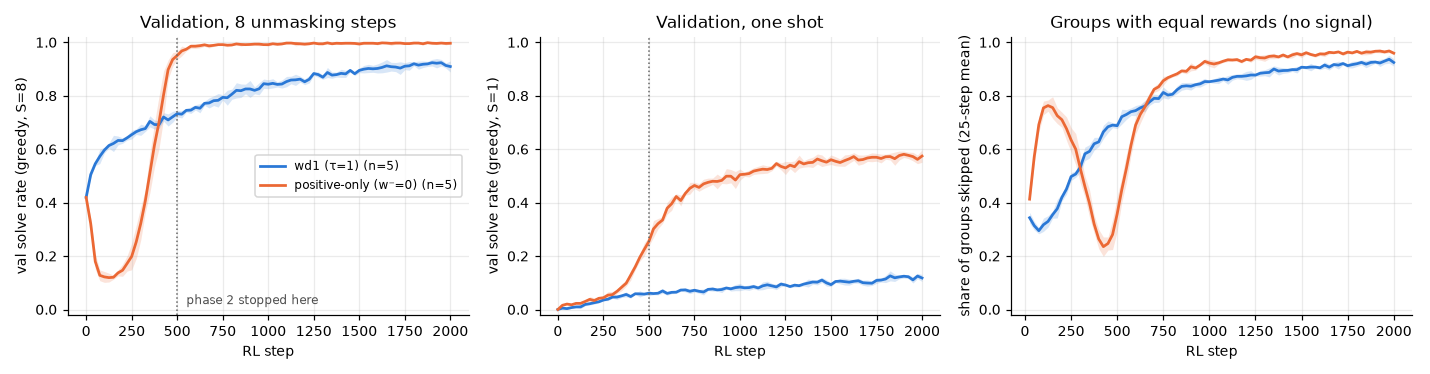

{'first_step_within_0.02_of_step_2000': 1450, 'first_step_staying_within_0.02': 1500, 'rule_horizon': 1500}


In [3]:
show("3.1a", "val_by_step.csv", "horizon.png"); print(json.load(open(R / "3.1a" / "horizon.json")))

## 3.1b Sharp weights

With 0/1 rewards and τ = 1 the softmax weights are nearly flat: about half of the positive weight falls on *invalid* rollouts. Lower τ makes them selective.

**Shows:** positive-only's early collapse disappears when the weights are selective (τ ≤ 0.1). wd1 does not care about τ at all.
**Does not show:** that flat weights are the only cause of the collapse.

,variant,tau,w_pos_on_invalid_steps_1_50,min_val_mean,final_val_mean,final_test_mean,final_test_std
0,positive-only,0.05,0.000e+00,0.420,0.995,0.998,5.000e-04
1,positive-only,0.10,1.000e-04,0.420,0.996,0.997,1.300e-03
2,positive-only,0.25,4.830e-02,0.407,0.996,0.997,5.000e-04
3,positive-only,1.00,4.489e-01,0.108,0.993,0.996,3.700e-03
4,wd1,0.05,0.000e+00,0.420,0.895,0.884,3.800e-03
5,wd1,0.10,1.000e-04,0.420,0.898,0.885,9.000e-03
6,wd1,0.25,3.860e-02,0.420,0.890,0.874,1.200e-02
7,wd1,1.00,3.608e-01,0.420,0.895,0.860,1.980e-02


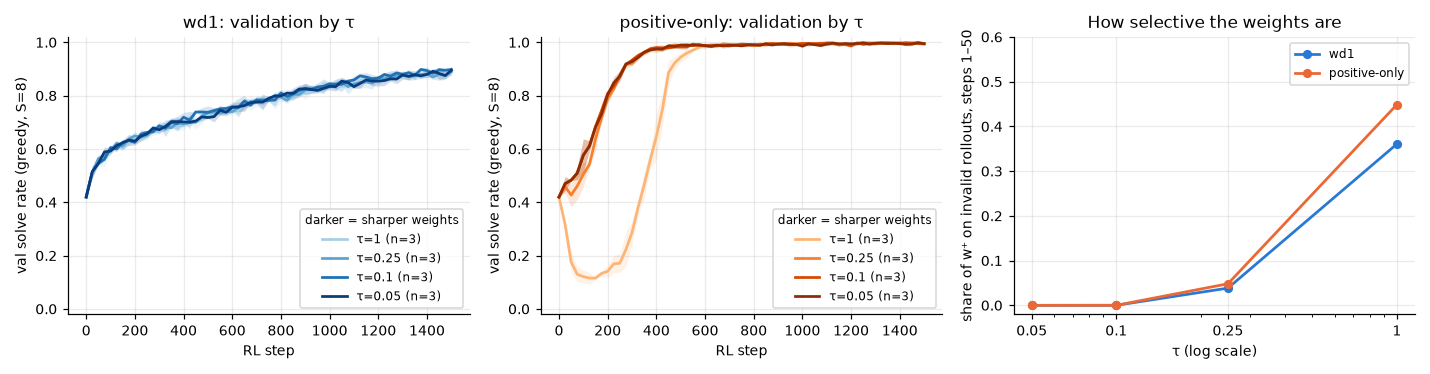

In [4]:
show("3.1b", "summary.csv", "tau_sweep.png", ["variant", "tau", "w_pos_on_invalid_steps_1_50", "min_val_mean", "final_val_mean", "final_test_mean", "final_test_std"])

## 3.1c How much negative push?

wd1 and positive-only are the two ends of one family, loss = Σ (β·w⁻ − w⁺)·log p̂. The table also has a floored negative term, which stops pushing a rollout down once its estimated log-likelihood is below a floor (not from the wd1 paper).

**Shows:** a cliff, not a slope. Any β below 1 ends near 100%, β = 1 (wd1) ends at 0.86, and β = 2 destroys the model. A floor at −12 lifts wd1 to 0.99.
**Does not show:** that β = 1 is a bad choice in general, or that −12 is a recipe.

,tau,beta,min_val_mean,final_test_mean,final_test_std
0,0.25,0.00,0.407,0.997,5.000e-04
1,0.25,0.25,0.420,0.996,5.000e-04
2,0.25,0.50,0.420,0.993,2.600e-03
3,0.25,1.00,0.420,0.874,1.200e-02
4,0.25,2.00,0.000,0.000,0.000e+00
5,1.00,0.00,0.108,0.996,3.700e-03
6,1.00,0.25,0.160,0.996,5.000e-04
7,1.00,0.50,0.349,0.996,2.700e-03
8,1.00,1.00,0.420,0.860,1.980e-02
9,1.00,2.00,0.000,0.000,0.000e+00


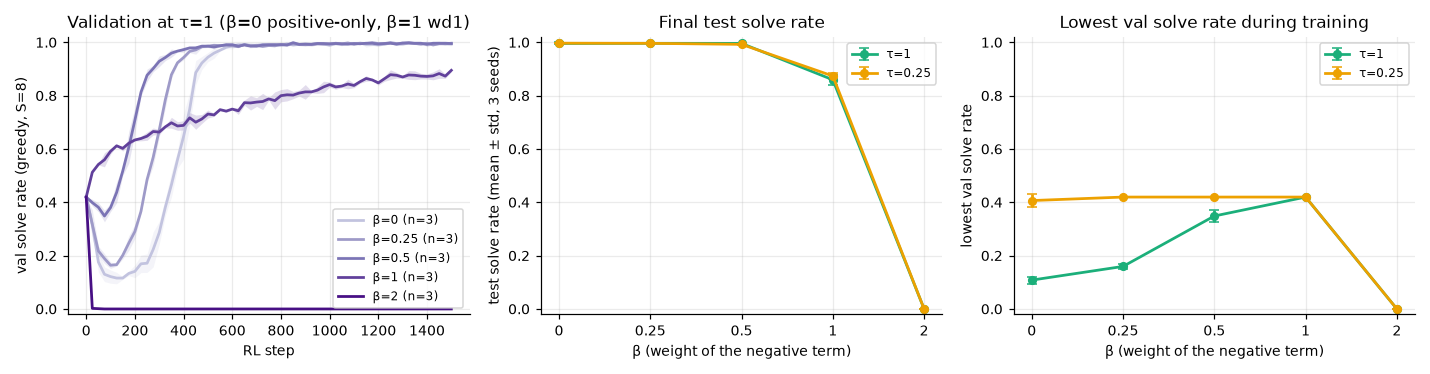

,floor,final_test_mean,final_test_std,final_test_s1_mean,logp_valid_last_250_steps
0,-12,0.991,0.002,0.311,-5.899
1,-15,0.985,0.003,0.231,-6.351
2,none,0.860,0.020,0.078,-12.486


In [5]:
show("3.1c", "summary.csv", "beta_sweep.png", ["tau", "beta", "min_val_mean", "final_test_mean", "final_test_std"])
show("3.1c", "floor.csv", cols=["floor", "final_test_mean", "final_test_std", "final_test_s1_mean", "logp_valid_last_250_steps"])

## 3.1d The starting model

Phase 2 started from one early snapshot of a model that was about to become good. Here: an earlier and a later snapshot, and a model trained to convergence on only 10 of the 200 solutions.

**Shows:** the phase 2 ranking is a property of that snapshot. Positive-only (τ = 1) wins from the two mid-warm-up snapshots, goes to zero from the earlier one, and rises then collapses from the converged model. wd1 improves from every start.
**Does not show:** how the safer variants behave from these starts; that is 3.1g below.

,n_solutions,n_puzzles,final_val_solve,final_seen_solutions_solve,final_unseen_train_solve,chosen
0,2,263,0.003,1.0,0.000,False
1,5,635,0.095,1.0,0.066,False
2,10,1289,0.649,1.0,0.672,True
3,20,2575,0.964,1.0,0.971,False
4,40,5091,0.993,1.0,0.993,False


,start,variant,start_val,final_val_mean,final_test_mean,final_test_std,min_val_mean
0,SFT step 100,wd1 (τ=1),0.115,0.897,0.879,0.004,0.115
1,SFT step 100,positive-only (w⁻=0),0.115,0.000,0.000,0.000,0.000
2,SFT step 120 (phase 2 start),wd1 (τ=1),0.420,0.895,0.860,0.020,0.420
3,SFT step 120 (phase 2 start),positive-only (w⁻=0),0.420,0.993,0.996,0.004,0.108
4,SFT step 130,wd1 (τ=1),0.567,0.916,0.916,0.016,0.567
5,SFT step 130,positive-only (w⁻=0),0.567,0.996,0.997,0.002,0.347
6,converged on 10 solutions,wd1 (τ=1),0.649,0.867,0.791,0.011,0.649
7,converged on 10 solutions,positive-only (w⁻=0),0.649,0.454,0.480,0.100,0.309


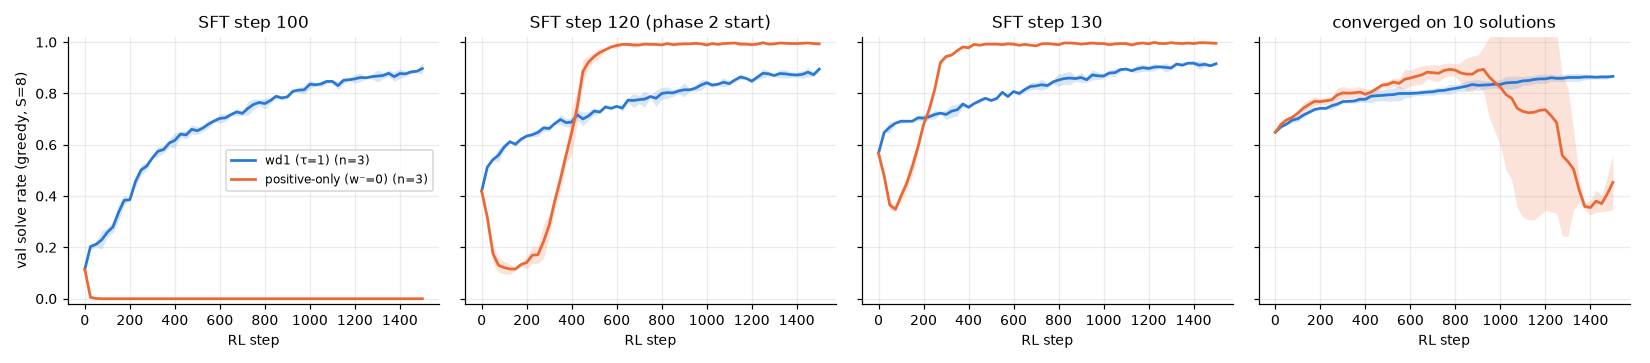

In [6]:
show("3.1d", "sft_subset_summary.csv", cols=["n_solutions", "n_puzzles", "final_val_solve", "final_seen_solutions_solve", "final_unseen_train_solve", "chosen"])
show("3.1d", "summary.csv", "starting_model.png", ["start", "variant", "start_val", "final_val_mean", "final_test_mean", "final_test_std", "min_val_mean"])

## 3.1e A graded reward

Reward = share of the 12 rows, columns and boxes that are valid, instead of 0/1.

**Shows:** no gain for wd1, and positive-only collapses to zero even at the temperature that was safe with the binary reward, because the rewards within a group are now close together and the weights are flat again.
**Does not show:** what much sharper or rank-based weights would do.

,tau,variant,reward,frac_skipped_steps_1_300,val_at_300,final_test_mean,final_test_std
0,0.25,positive-only (w⁻=0),binary,0.237,0.921,0.997,5.000e-04
1,0.25,positive-only (w⁻=0),graded,0.315,0.000,0.000,0.000e+00
2,0.25,wd1 (τ=1),binary,0.390,0.683,0.874,1.200e-02
3,0.25,wd1 (τ=1),graded,0.117,0.674,0.863,1.190e-02
4,1.00,positive-only (w⁻=0),binary,0.667,0.286,0.996,3.700e-03
5,1.00,positive-only (w⁻=0),graded,0.385,0.000,0.000,0.000e+00
6,1.00,wd1 (τ=1),binary,0.397,0.663,0.860,1.980e-02
7,1.00,wd1 (τ=1),graded,0.120,0.661,0.848,5.600e-03


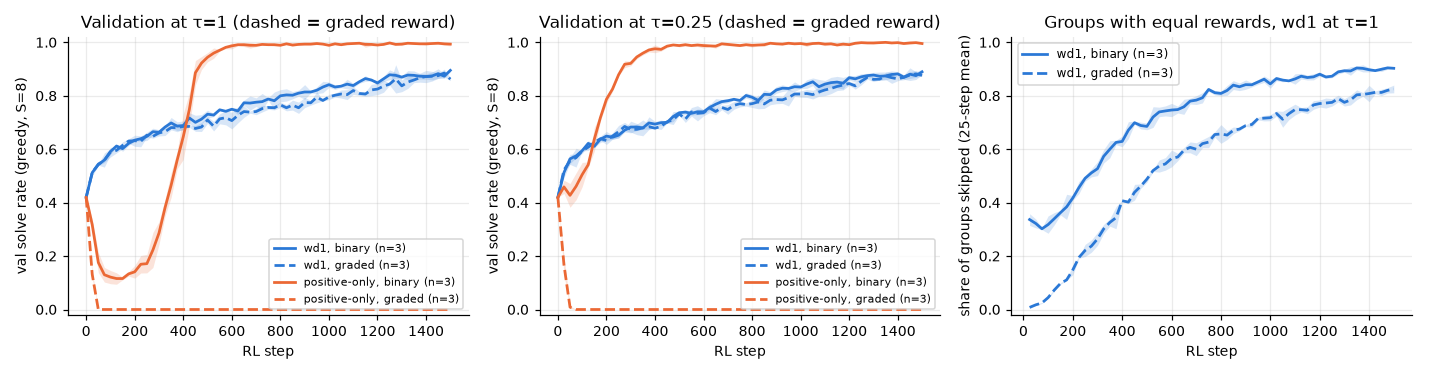

In [7]:
show("3.1e", "summary.csv", "graded_reward.png", ["tau", "variant", "reward", "frac_skipped_steps_1_300", "val_at_300", "final_test_mean", "final_test_std"])

## 3.1f A reference policy in the rollouts

The upstream wd1 code has no reference term in its loss. Its reference-policy variant mixes the reference model's logits into the *sampling*. This is the toy equivalent.

**Shows:** little change. All mixes are within 0.016 of plain wd1 on val.
**Does not show:** whether the 4-point difference on test is real; 3 seeds cannot tell.

,ref_mix,final_val_mean,final_test_mean,final_test_std,frac_skipped_last_250_steps
0,0.00,0.895,0.860,0.020,0.898
1,0.04,0.904,0.904,0.005,0.886
2,0.20,0.906,0.897,0.008,0.865
3,0.50,0.911,0.896,0.007,0.801


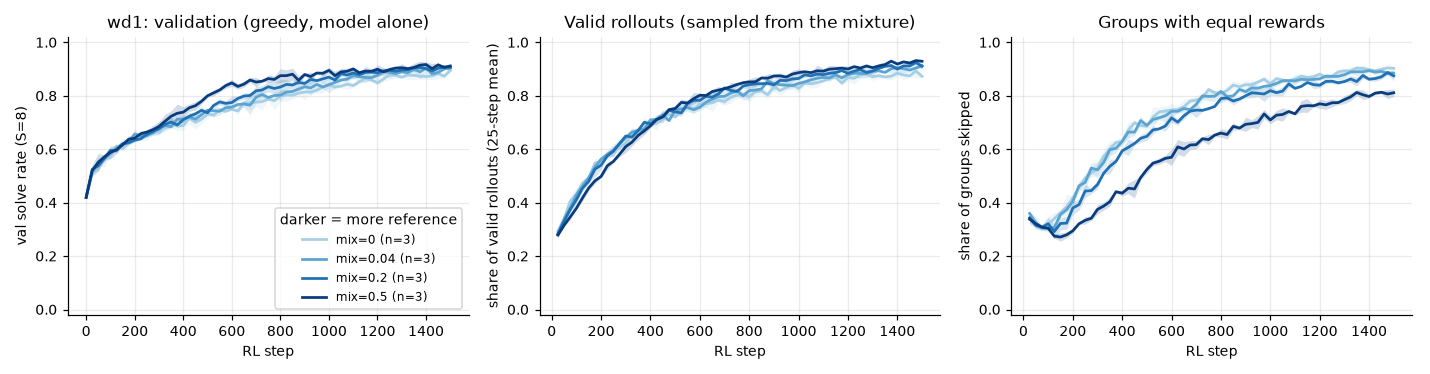

In [8]:
show("3.1f", "summary.csv", "reference_mix.png", ["ref_mix", "final_val_mean", "final_test_mean", "final_test_std", "frac_skipped_last_250_steps"])

## 3.2 wd1 next to simpler objectives

Same rollouts, same likelihood estimate, same budget, 5 seeds.

**Shows:** plain REINFORCE gives wd1's curve, so the softmax weighting is not what matters here. Imitating one's own valid rollouts gets to about 100% without labels. d1-style GRPO is clearly better than wd1.
**Does not show:** that imitation beats wd1 in general: valid rollouts are plentiful and always correct in this task.

,method,n,final_test_mean,final_test_std,final_test_s1_mean,min_val_mean,first_step_val_07_median
0,supervised reference (labels),5,1.000,0.000e+00,0.736,0.420,100.0
1,"self-training, SFT loss",5,0.999,6.000e-04,0.726,0.420,200.0
2,filtered imitation,5,0.997,1.000e-03,0.567,0.420,175.0
3,positive-only (w⁻=0),5,0.996,2.700e-03,0.579,0.112,400.0
4,d1-style GRPO,5,0.977,4.600e-03,0.100,0.420,225.0
5,"REINFORCE, normalised",5,0.885,1.340e-02,0.080,0.420,350.0
6,REINFORCE,5,0.884,9.700e-03,0.081,0.420,400.0
7,wd1 (τ=1),5,0.865,1.900e-02,0.082,0.420,425.0


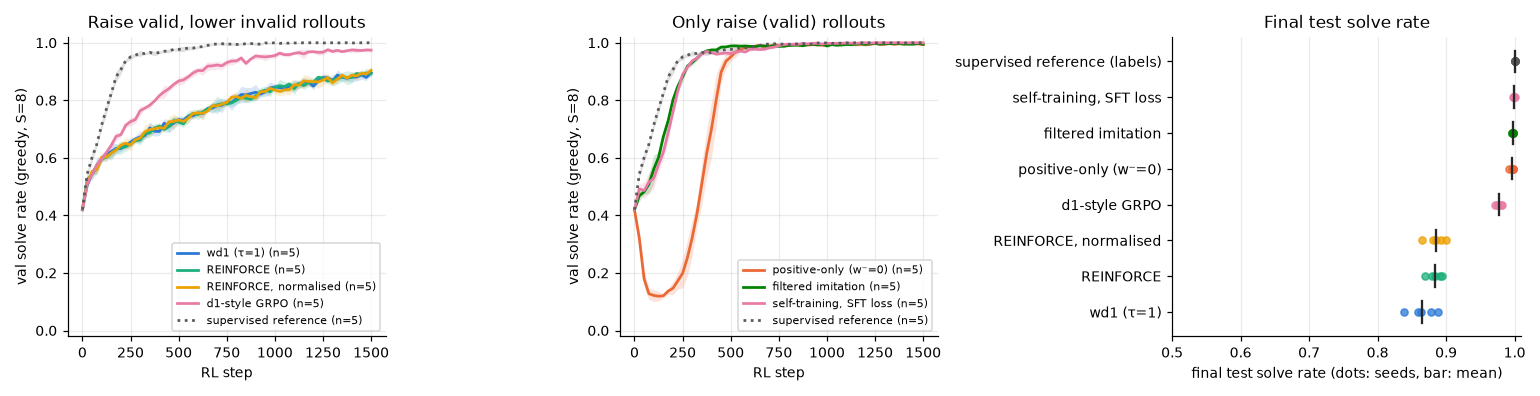

In [9]:
show("3.2", "summary.csv", "objectives.png", ["method", "n", "final_test_mean", "final_test_std", "final_test_s1_mean", "min_val_mean", "first_step_val_07_median"])

## 3.2b Why GRPO did better: the KL term to the starting model

GRPO's clipping never became active, so what separates it from REINFORCE is its KL penalty towards the starting model. Remove it from GRPO, add it to REINFORCE and to wd1.

**Shows:** the KL term is the whole difference. wd1 with a small KL penalty reaches 0.976.
**Does not show:** that wd1 needs a KL term at scale. The weight needed tuning (0.01 worked, 0.04 did not).

,arm,final_test_mean,final_test_std,logp_valid_last_250_steps,frac_skipped_last_250_steps
0,GRPO (KL 0.04),0.978,0.006,-7.814,0.766
1,REINFORCE + KL 0.04,0.978,0.001,-7.959,0.769
2,wd1 + KL 0.01,0.976,0.005,-7.974,0.768
3,wd1 + KL 0.04,0.896,0.003,-7.950,0.430
4,REINFORCE,0.880,0.011,-12.195,0.889
5,"GRPO, KL removed",0.871,0.006,-12.277,0.901
6,wd1,0.860,0.020,-12.486,0.898


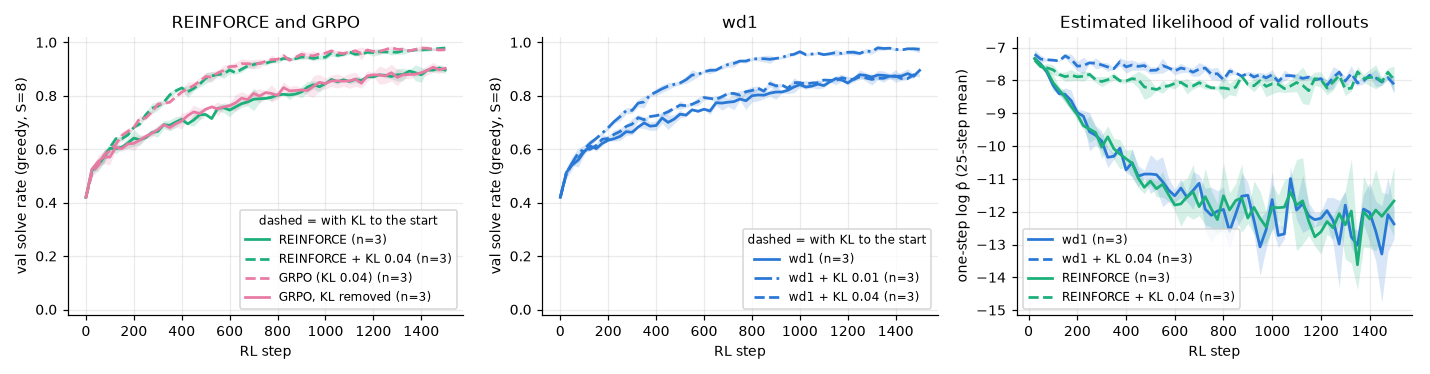

In [10]:
show("3.2b", "summary.csv", "kl_to_start.png", ["arm", "final_test_mean", "final_test_std", "logp_valid_last_250_steps", "frac_skipped_last_250_steps"])

## 3.1g Do the better variants survive other starting models?

The four variants that beat wd1 from the phase 2 start, rerun from the two harder starts of 3.1d.

**Shows:** self-training with the SFT loss on the model's own valid rollouts reaches about 100% from all three starts. The floored wd1 is the most robust wd1 variant (0.99, 0.99, 0.89). A KL penalty to the start helps from an unfinished model and hurts from a converged weak one. Plain wd1 is never the best and never fails.
**Does not show:** that self-training is better in general: here a valid rollout is always a correct answer and valid rollouts exist from the start.

,start,arm,final_test_mean,final_test_std,best_test_mean,max_drop_from_best_val
0,SFT step 100,"self-training, SFT loss",0.999,1.400e-03,0.995,0.000
1,SFT step 100,filtered imitation,0.996,8.000e-04,0.991,0.013
2,SFT step 100,"wd1, floor −12",0.989,2.700e-03,0.988,0.006
3,SFT step 100,wd1 + KL 0.01,0.982,1.700e-03,0.980,0.013
4,SFT step 100,wd1 (τ=1),0.879,3.900e-03,0.874,0.007
5,SFT step 100,positive-only (w⁻=0),0.000,0.000e+00,0.152,0.115
6,converged on 10 solutions,"self-training, SFT loss",1.000,0.000e+00,0.995,0.000
7,converged on 10 solutions,"wd1, floor −12",0.890,1.990e-02,0.879,0.003
8,converged on 10 solutions,filtered imitation,0.888,1.090e-02,0.878,0.000
9,converged on 10 solutions,wd1 (τ=1),0.791,1.110e-02,0.788,0.006


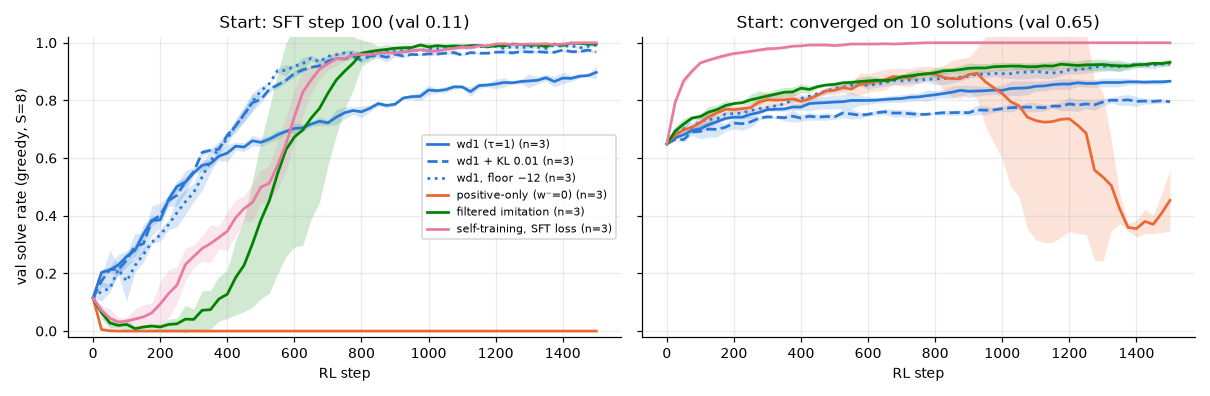

In [11]:
show("3.1g", "summary.csv", "other_starts.png", ["start", "arm", "final_test_mean", "final_test_std", "best_test_mean", "max_drop_from_best_val"])

## 3.3 Rewarding honest confidence

A 17th position reads the grid and states a confidence in one of four values. It is rewarded with r − (q − r)², which is highest for an honest q (idea from RLCR). The baseline needs no RL: recalibrate the confidence the model already has with a 2-parameter map.

**Shows:** trained together with the grid, the token does not become calibrated: it settles on one value early and stops exploring. The 2-parameter recalibration is far better.
**Does not show:** that the idea cannot work; the target was moving and the weights were flat. 3.3b removes both.

,checkpoint,test_solve,raw_mean,raw_brier,raw_ece,raw_auroc,platt_brier,platt_ece
0,weak,0.482,0.721,0.285,0.251,0.816,0.176,0.051
1,wd1_seed0,0.838,0.980,0.147,0.141,0.923,0.068,0.021
2,wd1_seed1,0.863,0.982,0.126,0.119,0.905,0.071,0.025
3,wd1_seed2,0.878,0.982,0.111,0.104,0.930,0.061,0.014


,arm,solve_mean,base_rate_brier_mean,q_expected_brier_mean,q_expected_brier_std,q_expected_ece_mean,q_expected_auroc_mean
0,"token first, probe",0.880,0.105,0.171,0.004,0.255,0.560
1,"token first, rl",0.874,0.110,0.359,0.004,0.499,0.446
2,"token last, probe",0.882,0.104,0.279,0.127,0.479,0.934
3,"token last, rl",0.867,0.116,0.296,0.106,0.408,0.516


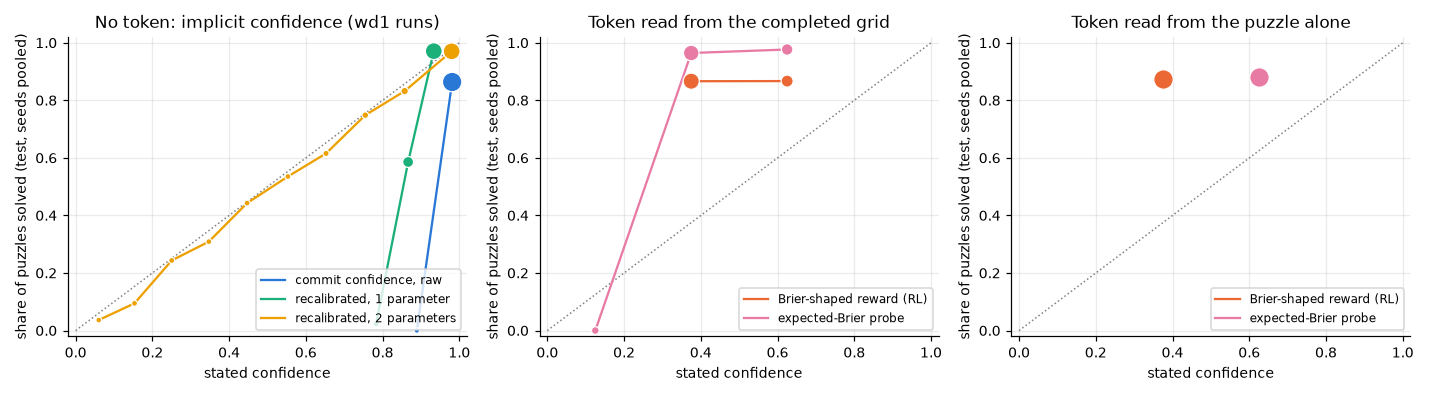

In [12]:
base = pd.read_csv(R / "3.3" / "baseline_implicit.csv")
display(base[["checkpoint", "test_solve", "raw_mean", "raw_brier", "raw_ece", "raw_auroc", "platt_brier", "platt_ece"]])
show("3.3", "summary.csv", "calibration.png", ["arm", "solve_mean", "base_rate_brier_mean", "q_expected_brier_mean", "q_expected_brier_std", "q_expected_ece_mean", "q_expected_auroc_mean"])

## 3.3b The confidence token on a frozen denoiser

Same token, but the denoiser is frozen (the wd1 checkpoints from 3.1b), so the target is stationary; RL is plain REINFORCE on the Brier-shaped reward.

**Shows:** the token learns to verify its own grid (AUROC 0.93 with RL, 0.98 with the probe) and beats the best post-hoc recalibration on the Brier score. Read from the puzzle alone, it states the base rate.
**Does not show:** uncertainty about a reasoning process; checking a finished 4×4 grid is easy for this architecture.

,arm,solve_mean,base_rate_brier_mean,q_expected_brier_mean,q_expected_brier_std,q_expected_ece_mean,q_expected_auroc_mean
0,"token first, probe",0.86,0.12,0.121,0.015,0.017,0.658
1,"token first, rl",0.86,0.12,0.121,0.015,0.017,0.577
2,"token last, probe",0.86,0.12,0.032,0.007,0.135,0.980
3,"token last, rl",0.86,0.12,0.047,0.009,0.127,0.932


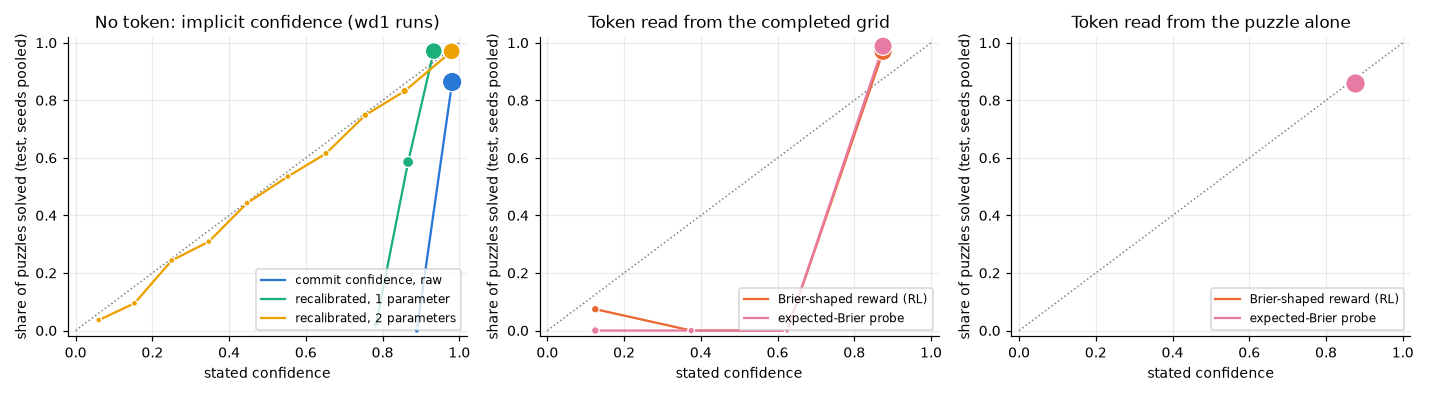

In [13]:
show("3.3b", "summary.csv", "calibration.png", ["arm", "solve_mean", "base_rate_brier_mean", "q_expected_brier_mean", "q_expected_brier_std", "q_expected_ece_mean", "q_expected_auroc_mean"])

## 3.4a Is there headroom in the unmasking order?

The weak denoiser is frozen and one cell is committed per step. An oracle that knows the solution always commits a cell whose prediction is right.

**Shows:** a large gap: 0.98 for the oracle against 0.56 for the confidence rule. A correct next move almost always exists.
**Does not show:** that a policy without the solution can find it.

In [14]:
display(pd.read_csv(R / "3.4a" / "oracle.csv").query("split == 'test'"))
display(pd.read_csv(R / "3.4a" / "oracle_by_hidden_cells.csv"))

,split,order,n,solve_rate,ci_lo,ci_hi
5,test,random,1194,0.144,0.125,0.164
6,test,confidence,1194,0.559,0.530,0.588
7,test,margin,1194,0.538,0.510,0.567
8,test,entropy,1194,0.462,0.433,0.489
9,test,oracle,1194,0.984,0.977,0.991


,k,oracle,confidence
0,6,0.994,0.869
1,7,0.983,0.795
2,8,0.977,0.756
3,9,0.972,0.574
4,10,1.000,0.443
5,11,0.983,0.204
6,12,0.978,0.196


### Live demo: confidence order against oracle order on one puzzle

A single 12-hidden-cell test puzzle, decoded twice with the frozen weak denoiser. This is one example, not a measurement.

In [15]:
if HAVE_CKPT:
    from phase2.data import PuzzleSet, build_datasets
    from phase2.sampler import sample
    from phase2.sudoku import to_str
    from phase3.order_policy import load_denoiser, oracle_order
    base = load_cfg("configs/phase2.yaml")
    test = build_datasets(base, 0)["test"]
    m = load_denoiser(base, CACHE / "sft" / "sft_weak.pt", "cpu")
    hard = (test.k == 12).nonzero().squeeze(1)
    conf = sample(m, test.puzzles[hard], 16, "confidence", 0.0)
    orc = oracle_order(m, test.subset(hard))["solved"]
    ok_conf = (conf.grid == test.solutions[hard]).all(1)
    i = int((orc & ~ok_conf).nonzero()[0])      # first puzzle the oracle solves and the confidence rule does not
    print("puzzle:"); print(to_str(test.puzzles[hard][i].tolist()))
    print("\nconfidence order (compare with the solution below):"); print(to_str(conf.grid[i].tolist()))
    print("\nsolution, reached by the oracle order with the same denoiser:"); print(to_str(test.solutions[hard][i].tolist()))
    print("\ncommit step per cell under the confidence rule (-1 = given):"); print(conf.commit_step[i].view(4, 4).numpy())
    print("\n12-hidden-cell test puzzles solved: confidence", round(ok_conf.float().mean().item(), 3), "| oracle", round(orc.float().mean().item(), 3))
else:
    print("checkpoint not present locally; skipping live demo")

puzzle:
. . | . 1
. 2 | . .
----+----
. 3 | . .
. . | . 4

confidence order (compare with the solution below):
4 1 | 3 1
3 2 | 4 2
----+----
2 3 | 1 3
1 4 | 2 4

solution, reached by the oracle order with the same denoiser:
3 4 | 2 1
1 2 | 4 3
----+----
4 3 | 1 2
2 1 | 3 4

commit step per cell under the confidence rule (-1 = given):
[[ 2  7  0 -1]
 [ 8 -1  9 10]
 [ 5 -1 11  6]
 [ 3  4  1 -1]]

12-hidden-cell test puzzles solved: confidence 0.196 | oracle 0.978


## 3.4b Learning the order with RL

A small head scores every masked cell; training is REINFORCE on the validity reward. Here the log-probability of an order is exact, unlike the denoiser's likelihood.

**Shows:** from the three heuristic scores RL rediscovers the confidence rule in about 50 steps. With the denoiser's hidden state it finds an order 11 points better, about a quarter of the way to the oracle. That policy does not transfer to other denoisers.
**Does not show:** that the rest of the gap can be learned; a head trained *with* the solutions does no better.

,variant,n,final_test_mean,final_test_std,final_val_mean,agree_with_confidence,lr
0,"RL, + hidden state, confidence start",5,0.668,0.016,0.658,0.766,0.010
1,"teacher (uses solutions), + hidden state",3,0.644,0.021,0.618,0.694,0.010
2,"RL, + hidden state, random start",5,0.619,0.084,0.622,0.730,0.010
3,"RL, 3 heuristic scores, random start",5,0.567,0.002,0.582,0.963,0.003
4,"RL, 3 heuristic scores, confidence start",5,0.567,0.001,0.582,0.964,0.003
5,"teacher (uses solutions), 3 scores",3,0.562,0.001,0.555,0.954,0.003


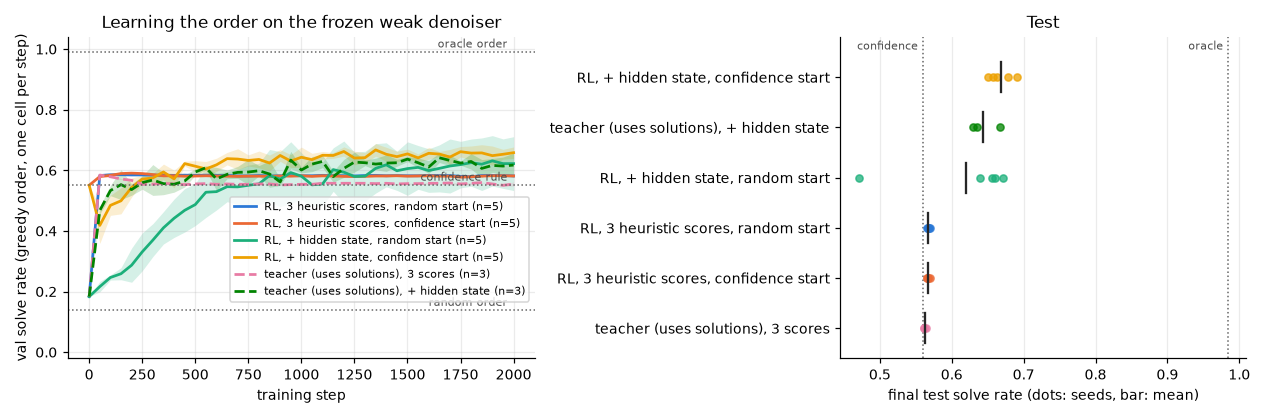

,denoiser,order,n,test_solve_mean,test_solve_std
0,sft100,confidence rule,1,0.169,NaN
1,sft100,random rule,1,0.044,NaN
2,sft100,oracle,1,0.867,NaN
3,sft100,"policy probs, zero start",5,0.170,4.000e-04
4,sft100,"policy hidden, zero start",5,0.086,1.420e-02
5,sft100,"policy hidden, confidence start",5,0.097,1.070e-02
6,sft120,confidence rule,1,0.559,NaN
7,sft120,random rule,1,0.147,NaN
8,sft120,oracle,1,0.984,NaN
9,sft120,"policy probs, zero start",5,0.566,4.000e-04


In [16]:
show("3.4b", "summary.csv", "order_policy.png")
show("3.4b", "transfer_summary.csv")

## Summary

See `results/phase3/SUMMARY.md` for the tables, the prediction scorecard, the run notes and the limitations.